In [3]:
import pandas as pd
import numpy as np 
import warnings
import seaborn as sns
import math
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr
import os
import glob


In [4]:
weather_data = pd.read_csv("C:/Users/leste/OneDrive/Desktop/Microsoft VS Code/Github/Data-Science-Portfolio/Data Files/Polynomial Regression/Temperature data.csv")

In [5]:
weather_data

,x,y
0,1.409445,5.275026
1,-9.337377,212.625146
2,-6.951291,124.721516
3,3.781497,20.279580
4,-5.841269,93.034061
...,...,...
995,8.376568,117.422861
996,8.072793,111.887072
997,-4.594724,59.801025
998,1.498651,4.401643


<Axes: xlabel='x', ylabel='y'>

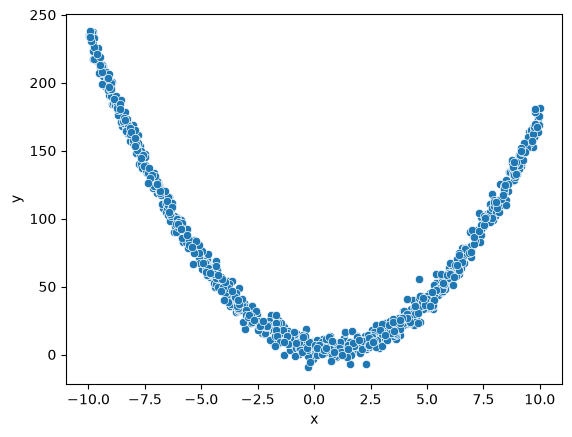

In [6]:
sns.scatterplot(x = weather_data['x'] , y = weather_data['y'])

<Axes: ylabel='x'>

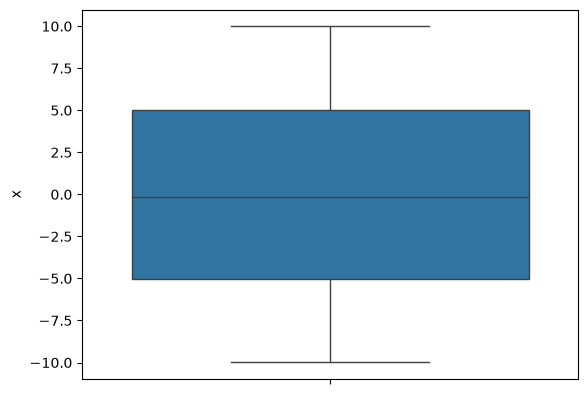

In [7]:
sns.boxplot(weather_data['x']) # x feature

<Axes: ylabel='y'>

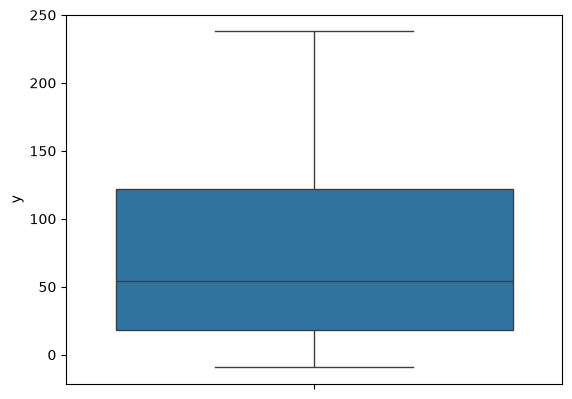

In [8]:
sns.boxplot(weather_data['y']) #y feature

### Polynomial Regression

In [9]:
standard_scaling = StandardScaler()

In [11]:
poly = PolynomialFeatures(degree = 3)

In [17]:
x = weather_data[['x']]
y = weather_data[['y']]

In [18]:
x_train,x_temp,y_train,y_temp = train_test_split(x,y,test_size = 0.2, random_state = 42)

x_val , x_test , y_val , y_test = train_test_split(x_temp , y_temp , test_size = 0.5 , random_state = 42)

> Plotting  Validation data

> Transforming the input feature into the polynomial features

In [19]:
x_poly_train = poly.fit_transform(x_train)
x_poly_val = poly.fit_transform(x_val)

In [ ]:
poly.fit(x_poly_train,y_train)


PolynomialFeatures(degree=3)

In [24]:
model = LinearRegression()

In [25]:
model.fit(x_poly_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 4)","[[ 0. ,-2.99, 2. ,-0. ]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.34]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[10957.41, 855.09, 65.01, 0. ]"


In [26]:
y_pred_val = model.predict(x_poly_val)
y_pred_train = model.predict(x_poly_train)

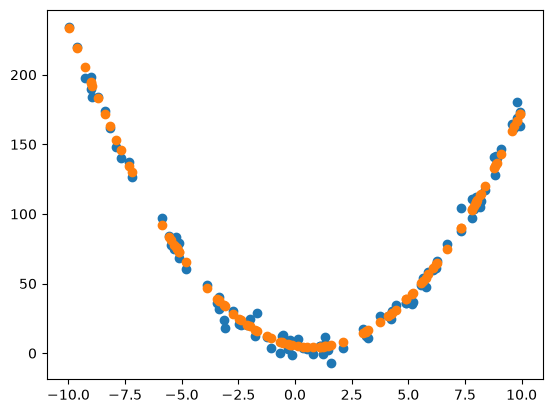

In [27]:
plt.scatter(x_val , y_val)
plt.scatter(x_val, y_pred_val)

In [ ]:
print(f"The training MSE test error is : {mean_squared_error(y_pred_train,y_train)}")
print(f"The validation MSE test error is : {mean_squared_error(y_pred_val,y_val)}")

The training MSE test error is : 22.09042393864609
The validation MSE test error is : 27.970904723423622


In [ ]:
print(f"The training MAE test error is : {mean_absolute_error(y_pred_train,y_train)}")
print(f"The validation MAE test error is : {mean_absolute_error(y_pred_val,y_val)}")

The training MAE test error is : 3.7418552618450622
The validation MAE test error is : 4.222311395000658


In [30]:
model.score(x_poly_train,y_train)

0.9945314449024082

In [31]:
model.score(x_poly_val,y_val)

0.9929821824781332

In [32]:
r2_score(y_train,y_pred_train)

0.9945314449024082